# Molecular docking -- Lavandula_stoechas vs AChE (1EVE)

Protein: Acetylcholinesterase (Torpedo californica), PDB 1EVE, native ligand E2020/donepezil (code E20, monomer -- no chain selection needed, unlike the COX-2/5IKQ homodimer). Compounds: Fenchone, Camphor, p-Cymene, alpha-Pinene (Dob et al. 2006). Docking box is derived from E20's real position (Section 7.1), not a hardcoded fallback -- same validated approach used for COX-2.

## Content of this notebook

1. Feching system and cleanup
2. Protein and ligand sanitization
3. System Visualization 
4. Docking with AutoDock Vina
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - PDBQT results file conversion to SDF
    - 3D visualization of docking results
    - 2D interaction table and map
5. Docking with Smina
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - 3D visualization of docking results
    - 2D interaction table and map
6. Docking with LeDock
    - Receptor preparation
    - Ligand preparation
    - Docking box definition
    - Docking
    - DOK results file conversion to SDF
    - 3D visualization of docking results
    - 2D interaction table and map

In [1]:
from pymol import cmd
import py3Dmol

from vina import Vina

from openbabel import pybel

from rdkit import Chem
from rdkit.Chem import AllChem, Draw

from meeko import MoleculePreparation

import MDAnalysis as mda
from MDAnalysis.coordinates import PDB

import prolif as plf
from prolif.plotting.network import LigNetwork


import sys, os
sys.path.insert(1, "/home/ali/medical plants/docking/Jupyter_Dock-main/utilities/")
from utils import fix_protein, getbox, generate_ledock_file, pdbqt_to_sdf, dok_to_sdf


import warnings
warnings.filterwarnings("ignore")
%config Completer.use_jedi = False

/home/ali/Downloads/or/envs/jupdock_clean/lib/python3.10/site-packages/MDAnalysis/topology/tables.py:52: DeprecationWarning: Deprecated in version 2.8.0
MDAnalysis.topology.tables has been moved to MDAnalysis.guesser.tables. This import point will be removed in MDAnalysis version 3.0.0
  warnings.warn(wmsg, category=DeprecationWarning)


It's a good idea to run the test protocols before attempting custom projects. Later, the user can specify the location of his/her project and save all of the files separately.

In [2]:
os.chdir('/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/')


## 1. Feching system and cleanup

Implementing Pymol is a simple way to download PDB structures. The user can launch this or any other Jupyter Dock's protocol by providing his or her own files.

In [3]:
cmd.fetch(code='1EVE',type='pdb1')
cmd.select(name='Prot',selection='polymer.protein')
cmd.save(filename='1EVE_clean.pdb',format='pdb',selection='Prot',state=1)

# 1EVE's native ligand is E2020 (donepezil), PDB ligand code E20. Unlike
# COX-2/5IKQ, 1EVE is a monomer (not a homodimer), so no chain-specific
# selection is needed -- but state=1 is kept for consistency/safety.
cmd.select(name='NativeLig', selection='resn E20')
_natlig_model = cmd.get_model('NativeLig', state=1)
_natlig_resns = sorted(set((a.resn, a.chain) for a in _natlig_model.atom))
print("Native ligand residue(s) found (resn, chain):", _natlig_resns, "| atom count:", len(_natlig_model.atom))
cmd.save(filename='1EVE_native_lig.mol2', format='mol2', selection='NativeLig', state=1)
cmd.delete('all')


Native ligand residue(s) found (resn, chain): [('E20', 'A')] | atom count: 28


## 2. Protein and ligand sanitization

### 2.1. Protein Sanitization

#### Method 1: LePro

The Lephar molecular docking suite includes a very powerful tool for automatically preparing proteins for molecular docking. As a result, for these protocols, it will be the preferred tool for protein preparation. The protein prepared by LePro can be used in AutoDock VIna and LeDock.

In [4]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" # Launch this cell to see parameters


************************************************************
*      LePro                                               *
*            Add hydrogen atoms to a protein &             *
*            write the input file for LeDock               *
*      Copyright (C) 2013-21 Hongtao Zhao, PhD             *
*      Email: htzhaovv@gmail.com                           *
************************************************************
----------Usage:                                                                       
          lepro [PDB file] [-rot || -metal || -p]                                        
          -rot  [[chain] resid] align principal axes of the binding site with Cartesian
          -metal keep ZN/MN/CA/MG                                                      
          -metal -p redistribute metal charge to protein                               



In [5]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/lepro_linux_x86" {'1EVE_clean.pdb'}

os.rename('pro.pdb','1EVE_clean_H.pdb')


#### Method 2: fix_protein (PDBFixer)

For proteins with missing amino acids or residues, or to ensure a more thorough sanitization of protein Jupyter Dock includes the _fix_protein()_ function, which employs PDBFixer to correct a wide range of common errors in protein pdb files. Furthermore, PDBFixer enables the assignment of pH-dependent protonation states to proteins.


>**Warning 1:**  It is possible to encounter problems with protein fixing when using **_fix_protein()_** and AutoDock Tools' **_prepare_receptor_** or when running LeDock. To resolve the issue, it is best to set the parameter _-A hydrogens_ in _prepare receptor_.


>**Hint:** PDBFixer is a great solution for many systems because it can solve serious problems in PDB files. As a result, PDBFixer renumbers the residues beginning with 1 regardless of the numbering on the original PDB file. To address this issue, the **_fix_protein()_** function includes a protocol for atomically renumbering the residues in accordance with the original PDB file.


**_fix_protein ( params )_**

Params:
      
  - **filename**: _str or path-like_ ; input file containing protein struture to be modified, file extrension must be pdb

  - **addHs_pH**: _float_ ; Add hydrogens at user defined pH

  - **try_renumberResidues**: _bool_ ; By default PDBFixer renumarets residues starting in 1, this option tries to recover originar residues numbering
    
  - **output**: _str or path-like_ ; output filename, extension must be pdb

```
fix_protein(filename='1EVE_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1EVE_clean_H.pdb')
```

## 4. Docking with AutoDock Vina

AutoDock Vina (Vina) is one of the docking engines in the AutoDock Suite, together with AutoDock4 (AD4), AutoDockGPU, AutoDockFR, and AutoDock-CrankPep, and arguably among the most widely used and successful docking engines. The reasons for this success are mostly due to its ease of use and its speed (up to 100x faster than AD4), when compared to the other docking engines in the suite and elsewhere, as well as being open source.

### 4.1. Protein preparation

After sanitization, the protein docking preparation includes converting it to the PDBQT file format, which stores the atomic coordinates, partial charges, and AutoDock atom types for both the receptor and the ligand. 

>**Hint:** Despite the fact that the PDBQT format includes changes (Q) and atom types (T) for molecular docking. The charges are not required for Autodock Vina, which computes electrostatic interactions using its own force field. Although, when using AutoDock instead of AutoDock Vina, the Q term is required. More information can be found here:https://autodock-vina.readthedocs.io/en/latest/introduction.html

#### Method 1: AutoDock Tools prepare_receptor

The AutoDock Tools are the best way to prepare the receptor for AutoDock Vina. Nonetheless, AutoDock Tools is a comprehensive suite of programs and scripts that are difficult to manage. Jupyter Dock execute the **_prepare receptor_** and **_prepare_ligand_** functions on their own. As a result, obtaining proper PDBQT files for AutoDock Vina has never been easier.

>**Warning:** There is currently only one method for preparing a PDBQT file for a receptor. It is expected that new methods apart from AutoDock Tools executables will be included in the near future into Jupyter Dock.

In [6]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" #Lauch this cell to see parameters


prepare_receptor4: receptor filename must be specified.
Usage: prepare_receptor4.py -r filename

    Description of command...
         -r   receptor_filename 
        supported file types include pdb,mol2,pdbq,pdbqs,pdbqt, possibly pqr,cif
    Optional parameters:
        [-v]  verbose output (default is minimal output)
        [-o pdbqt_filename]  (default is 'molecule_name.pdbqt')
        [-A]  type(s) of repairs to make: 
             'bonds_hydrogens': build bonds and add hydrogens 
             'bonds': build a single bond from each atom with no bonds to its closest neighbor
             'hydrogens': add hydrogens
             'checkhydrogens': add hydrogens only if there are none already
             'None': do not make any repairs 
             (default is 'None')
        [-C]  preserve all input charges ie do not add new charges 
             (default is addition of gasteiger charges)
        [-p]  preserve input charges on specific atom types, eg -p Zn -p Fe
        [-U]  cle

In [7]:
!"/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_receptor" -v -r {'1EVE_clean_H.pdb'} -o {'1EVE_clean_H.pdbqt'}

# If this raises "UnboundLocalError: local variable 'bonds' referenced before
# assignment", use this fallback:
# import subprocess
# r = subprocess.run(["obabel", "1EVE_clean_H.pdb", "-O", "1EVE_clean_H.pdbqt", "-xr"],
#                     capture_output=True, text=True)
# print(r.stdout, r.stderr)


set verbose to  True
set receptor_filename to  1EVE_clean_H.pdb
set outputfilename to  1EVE_clean_H.pdbqt
read  1EVE_clean_H.pdb
setting up RPO with mode= automatic and outputfilename=  1EVE_clean_H.pdbqt
charges_to_add= gasteiger
delete_single_nonstd_residues= None


In [8]:
fix_protein(filename='1EVE_clean.pdb',addHs_pH=7.4,try_renumberResidues=True,output='1EVE_clean_H_fix.pdb')


## 7. Screening PHYTO compounds (Lavandula_stoechas) against AChE (1EVE)

Reuses the receptor (`1EVE_clean_H.pdb`/`.pdbqt`) and the docking box
(native ligand E20/donepezil, `state=1`) prepared above. Each compound
docked in its own cell with its own uniquely-named variables, seed pinned
at 42. Source: Dob et al. 2006.

In [9]:
import os
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolDescriptors
from openbabel import openbabel as ob
from vina import Vina
import pandas as pd
import matplotlib.pyplot as plt

DOCKING_DIR = "/home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/"
FIGURES_DIR = os.path.join(DOCKING_DIR, "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)
os.chdir(DOCKING_DIR)

RECEPTOR_PDB   = os.path.join(DOCKING_DIR, "1EVE_clean_H.pdb")
RECEPTOR_PDBQT = os.path.join(DOCKING_DIR, "1EVE_clean_H.pdbqt")
NATIVE_LIG     = os.path.join(DOCKING_DIR, "1EVE_native_lig.mol2")

assert os.path.exists(RECEPTOR_PDBQT), "Run the receptor prep cells above first."
assert os.path.exists(NATIVE_LIG), "Run the native ligand extraction cell above first."

VINA_SEED = 42  # pinned for reproducibility

def prepare_ligand_from_smiles(name, smiles, n_confs=20):
    """SMILES -> multiple 3D conformers (ETKDGv3) -> MMFF94 minimize each ->
    keep lowest-energy conformer -> PDB -> PDBQT (AutoDockTools prepare_ligand,
    with OpenBabel fallback)."""
    import subprocess
    m = Chem.MolFromSmiles(smiles)
    m = Chem.AddHs(m)

    params = AllChem.ETKDGv3()
    params.randomSeed = 42
    conf_ids = AllChem.EmbedMultipleConfs(m, numConfs=n_confs, params=params)

    energies = []
    for cid in conf_ids:
        ff = AllChem.MMFFGetMoleculeForceField(m, AllChem.MMFFGetMoleculeProperties(m), confId=cid)
        if ff is None:
            continue
        ff.Minimize(maxIts=2000)
        energies.append((ff.CalcEnergy(), cid))
    if not energies:
        for cid in conf_ids:
            ff = AllChem.UFFGetMoleculeForceField(m, confId=cid)
            ff.Minimize(maxIts=2000)
            energies.append((ff.CalcEnergy(), cid))

    best_energy, best_cid = min(energies, key=lambda x: x[0])
    print(f"  {name}: {len(conf_ids)} conformers generated, "
          f"lowest energy = {best_energy:.2f} kcal/mol (conf {best_cid})")

    pdb_path   = os.path.join(DOCKING_DIR, f'_lig_{name}.pdb')
    pdbqt_path = os.path.join(DOCKING_DIR, f'_lig_{name}.pdbqt')
    Chem.MolToPDBFile(m, pdb_path, confId=best_cid)

    PREP_LIG_BIN = "/home/ali/medical plants/docking/Jupyter_Dock-main/bin/prepare_ligand"
    result = subprocess.run([PREP_LIG_BIN, "-v", "-l", pdb_path, "-o", pdbqt_path],
                             capture_output=True, text=True)
    if not os.path.exists(pdbqt_path) or os.path.getsize(pdbqt_path) == 0:
        obConv = ob.OBConversion()
        obConv.SetInAndOutFormats('pdb', 'pdbqt')
        obmol = ob.OBMol()
        obConv.ReadFile(obmol, pdb_path)
        obConv.WriteFile(obmol, pdbqt_path)

    return pdbqt_path


### 7.1. Recompute the docking box (native ligand E20, `state=1`)

In [10]:
cmd.load(filename=RECEPTOR_PDB, format='pdb', object='prot', state=1)
cmd.load(filename=NATIVE_LIG, format='mol2', object='natlig', state=1)

center, size = getbox(selection='natlig', extending=5.0, software='vina')
cmd.delete('all')

print(center, '\n', size)


{'center_x': 2.0225000381469727, 'center_y': 63.295000076293945, 'center_z': 67.0615005493164} 
 {'size_x': 16.913000106811523, 'size_y': 21.296001434326172, 'size_z': 21.733001708984375}


### 7.2. Dock **Fenchone** against AChE (1EVE)

In [11]:
# ---- Fenchone (Lavandula_stoechas, Dob et al. 2006) ----
smiles_Fenchone = "CC1(C)C2CCC1(C)C(=O)C2"
lig_pdbqt_Fenchone = prepare_ligand_from_smiles("Fenchone", smiles_Fenchone)

v_Fenchone = Vina(sf_name='vina', seed=VINA_SEED)
v_Fenchone.set_receptor(RECEPTOR_PDBQT)
v_Fenchone.set_ligand_from_file(lig_pdbqt_Fenchone)
v_Fenchone.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Fenchone.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Fenchone = os.path.join(DOCKING_DIR, "Fenchone_1EVE_vina_out.pdbqt")
v_Fenchone.write_poses(vina_out_pdbqt_Fenchone, n_poses=10, overwrite=True)

energies_Fenchone = v_Fenchone.energies(n_poses=10)
best_score_Fenchone = round(float(energies_Fenchone[0][0]), 3)

print("=== Fenchone ===")
print(f"Best Vina score: {best_score_Fenchone} kcal/mol")
for i, e in enumerate(energies_Fenchone):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Fenchone = vina_out_pdbqt_Fenchone.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Fenchone, output=vina_out_sdf_Fenchone)


  Fenchone: 20 conformers generated, lowest energy = 45.56 kcal/mol (conf 9)
Computing Vina grid ... === Fenchone ===
Best Vina score: -6.695 kcal/mol
  Pose 1: -6.695
  Pose 2: -6.568
  Pose 3: -6.512
  Pose 4: -6.456
  Pose 5: -6.439
  Pose 6: -6.407
  Pose 7: -6.399
  Pose 8: -6.323
  Pose 9: -6.247
  Pose 10: -6.208
done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************


### 7.3. Dock **Camphor** against AChE (1EVE)

In [12]:
# ---- Camphor (Lavandula_stoechas, Dob et al. 2006) ----
smiles_Camphor = "CC1(C2CCC1(C(=O)C2)C)C"
lig_pdbqt_Camphor = prepare_ligand_from_smiles("Camphor", smiles_Camphor)

v_Camphor = Vina(sf_name='vina', seed=VINA_SEED)
v_Camphor.set_receptor(RECEPTOR_PDBQT)
v_Camphor.set_ligand_from_file(lig_pdbqt_Camphor)
v_Camphor.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_Camphor.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_Camphor = os.path.join(DOCKING_DIR, "Camphor_1EVE_vina_out.pdbqt")
v_Camphor.write_poses(vina_out_pdbqt_Camphor, n_poses=10, overwrite=True)

energies_Camphor = v_Camphor.energies(n_poses=10)
best_score_Camphor = round(float(energies_Camphor[0][0]), 3)

print("=== Camphor ===")
print(f"Best Vina score: {best_score_Camphor} kcal/mol")
for i, e in enumerate(energies_Camphor):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_Camphor = vina_out_pdbqt_Camphor.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_Camphor, output=vina_out_sdf_Camphor)


  Camphor: 20 conformers generated, lowest energy = 45.56 kcal/mol (conf 11)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.695          0          0
   2       -6.568      1.475      2.744
   3       -6.512      4.073      5.631
   4       -6.456      2.805      4.148
   5       -6.439      2.451      3.958
   6       -6.407      2.118      3.602
   7       -6.399      3.212      4.277
   8       -6.323      2.655       3.86
   9       -6.247      1.579      2.433
  10       -6.208      1.427      2.675
Computing Vina grid ... done.
=== Camphor ===Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************

Best Vina score: -6.696 kcal/mol
  Pose 1: -6.696
  Pose 2: -6.588
  Pose 3: -6.530
  Pose 4: -6.410
  Pose 5: -6.382
  Pose 6: -6.336
  Pose 7: -6.311
 

### 7.4. Dock **p_Cymene** against AChE (1EVE)

In [13]:
# ---- p_Cymene (Lavandula_stoechas, Dob et al. 2006) ----
smiles_p_Cymene = "Cc1ccc(C(C)C)cc1"
lig_pdbqt_p_Cymene = prepare_ligand_from_smiles("p_Cymene", smiles_p_Cymene)

v_p_Cymene = Vina(sf_name='vina', seed=VINA_SEED)
v_p_Cymene.set_receptor(RECEPTOR_PDBQT)
v_p_Cymene.set_ligand_from_file(lig_pdbqt_p_Cymene)
v_p_Cymene.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_p_Cymene.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_p_Cymene = os.path.join(DOCKING_DIR, "p_Cymene_1EVE_vina_out.pdbqt")
v_p_Cymene.write_poses(vina_out_pdbqt_p_Cymene, n_poses=10, overwrite=True)

energies_p_Cymene = v_p_Cymene.energies(n_poses=10)
best_score_p_Cymene = round(float(energies_p_Cymene[0][0]), 3)

print("=== p_Cymene ===")
print(f"Best Vina score: {best_score_p_Cymene} kcal/mol")
for i, e in enumerate(energies_p_Cymene):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_p_Cymene = vina_out_pdbqt_p_Cymene.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_p_Cymene, output=vina_out_sdf_p_Cymene)


  p_Cymene: 20 conformers generated, lowest energy = 25.13 kcal/mol (conf 4)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -6.696          0          0
   2       -6.588      1.192      2.772
   3        -6.53     0.9547       2.92
   4        -6.41      1.088      1.972
   5       -6.382      1.685      2.956
   6       -6.336      1.881      3.224
   7       -6.311      1.736      2.821
   8       -6.288      1.456      2.664
   9       -6.272      1.692      2.147
  10       -6.174      1.361      2.256
Computing Vina grid ... === p_Cymene ===
Best Vina score: -7.538 kcal/mol
  Pose 1: -7.538
  Pose 2: -7.480
  Pose 3: -7.324
  Pose 4: -6.786
  Pose 5: -6.714
  Pose 6: -6.677
  Pose 7: -6.607
  Pose 8: -6.544
  Pose 9: -6.523
  Pose 10: -6.282
done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|


### 7.5. Dock **alpha_Pinene** against AChE (1EVE)

In [14]:
# ---- alpha_Pinene (Lavandula_stoechas, Dob et al. 2006) ----
smiles_alpha_Pinene = "CC1=CCC2CC1C2(C)C"
lig_pdbqt_alpha_Pinene = prepare_ligand_from_smiles("alpha_Pinene", smiles_alpha_Pinene)

v_alpha_Pinene = Vina(sf_name='vina', seed=VINA_SEED)
v_alpha_Pinene.set_receptor(RECEPTOR_PDBQT)
v_alpha_Pinene.set_ligand_from_file(lig_pdbqt_alpha_Pinene)
v_alpha_Pinene.compute_vina_maps(center=[center['center_x'], center['center_y'], center['center_z']],
                     box_size=[size['size_x'], size['size_y'], size['size_z']])

v_alpha_Pinene.dock(exhaustiveness=10, n_poses=10)
vina_out_pdbqt_alpha_Pinene = os.path.join(DOCKING_DIR, "alpha_Pinene_1EVE_vina_out.pdbqt")
v_alpha_Pinene.write_poses(vina_out_pdbqt_alpha_Pinene, n_poses=10, overwrite=True)

energies_alpha_Pinene = v_alpha_Pinene.energies(n_poses=10)
best_score_alpha_Pinene = round(float(energies_alpha_Pinene[0][0]), 3)

print("=== alpha_Pinene ===")
print(f"Best Vina score: {best_score_alpha_Pinene} kcal/mol")
for i, e in enumerate(energies_alpha_Pinene):
    print(f"  Pose {i+1}: {e[0]:.3f}")

vina_out_sdf_alpha_Pinene = vina_out_pdbqt_alpha_Pinene.replace('.pdbqt', '.sdf')
pdbqt_to_sdf(pdbqt_file=vina_out_pdbqt_alpha_Pinene, output=vina_out_sdf_alpha_Pinene)


  alpha_Pinene: 20 conformers generated, lowest energy = 36.81 kcal/mol (conf 18)

mode |   affinity | dist from best mode
     | (kcal/mol) | rmsd l.b.| rmsd u.b.
-----+------------+----------+----------
   1       -7.538          0          0
   2        -7.48     0.8975       4.22
   3       -7.324     0.9765        4.4
   4       -6.786      1.929      4.368
   5       -6.714       2.24      5.666
   6       -6.677      2.801      5.815
   7       -6.607      1.724      5.103
   8       -6.544      1.309      2.244
   9       -6.523      2.341      4.276
  10       -6.282      2.738      4.606
Computing Vina grid ... done.
Performing docking (random seed: 42) ... 
0%   10   20   30   40   50   60   70   80   90   100%
|----|----|----|----|----|----|----|----|----|----|
***************************************************
=== alpha_Pinene ===
Best Vina score: -6.672 kcal/mol
  Pose 1: -6.672
  Pose 2: -6.582
  Pose 3: -6.553
  Pose 4: -6.502
  Pose 5: -6.386
  Pose 6: -6.326
  Pose 7

### 7.6. Total docking results table -- Lavandula_stoechas vs AChE (1EVE)

In [15]:
docking_rows_stoechas_AChE = [
    {"Compound": "Fenchone",     "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_Fenchone},
    {"Compound": "Camphor",      "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_Camphor},
    {"Compound": "p_Cymene",     "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_p_Cymene},
    {"Compound": "alpha_Pinene", "Target": "AChE (1EVE)", "Best_Vina_Score_kcal_mol": best_score_alpha_Pinene},
]

docking_df_stoechas_AChE = pd.DataFrame(docking_rows_stoechas_AChE).sort_values("Best_Vina_Score_kcal_mol").reset_index(drop=True)
docking_df_stoechas_AChE.to_csv(os.path.join(DOCKING_DIR, "lavandula_stoechas_vs_AChE_vina.csv"), index=False)
docking_df_stoechas_AChE


,Compound,Target,Best_Vina_Score_kcal_mol
0,p_Cymene,AChE (1EVE),-7.538
1,Camphor,AChE (1EVE),-6.696
2,Fenchone,AChE (1EVE),-6.695
3,alpha_Pinene,AChE (1EVE),-6.672


### 7.7. Figure -- docking score comparison, Lavandula_stoechas vs AChE

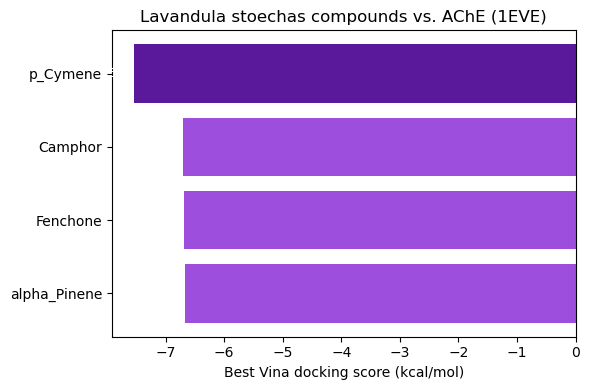

Saved figure: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/lavandula_stoechas_vs_AChE_scores.png


In [16]:
fig, ax = plt.subplots(figsize=(6, 4))
colors = ['#5a189a' if s == docking_df_stoechas_AChE['Best_Vina_Score_kcal_mol'].min() else '#9d4edd'
          for s in docking_df_stoechas_AChE['Best_Vina_Score_kcal_mol']]
ax.barh(docking_df_stoechas_AChE['Compound'], docking_df_stoechas_AChE['Best_Vina_Score_kcal_mol'], color=colors)
ax.set_xlabel('Best Vina docking score (kcal/mol)')
ax.set_title('Lavandula stoechas compounds vs. AChE (1EVE)')
ax.invert_yaxis()
for i, v in enumerate(docking_df_stoechas_AChE['Best_Vina_Score_kcal_mol']):
    ax.text(v - 0.15, i, f"{v:.2f}", va='center', ha='right', fontsize=9, color='white')
plt.tight_layout()

fig_path_stoechas_AChE = os.path.join(FIGURES_DIR, 'lavandula_stoechas_vs_AChE_scores.png')
plt.savefig(fig_path_stoechas_AChE, dpi=300, bbox_inches='tight')
plt.show()
print("Saved figure:", fig_path_stoechas_AChE)


### 7.8. ProLif interaction fingerprints -- Lavandula_stoechas vs AChE (each compound, own cell)

`n_jobs=1` avoids a multiprocessing/pickling crash in this environment;
`to_dataframe()` takes no arguments in ProLif 2.2.1.

In [17]:
prot_fp = mda.Universe("1EVE_clean_H_fix.pdb")  # fix_protein() output
prot_fp = plf.Molecule.from_mda(prot_fp)


In [20]:
# ---- Helper: render a ProLIF LigNetwork widget to a real PNG file ----
import os
import sys
import subprocess

_RENDER_WORKER_PATH = os.path.join(os.getcwd(), "_lignetwork_render_worker.py")

_RENDER_WORKER_SOURCE = '''
import sys
from playwright.sync_api import sync_playwright

html_path, png_path, width, height, wait_ms = sys.argv[1:6]
width, height, wait_ms = int(width), int(height), int(wait_ms)

with sync_playwright() as p:
    browser = p.chromium.launch()
    page = browser.new_page(viewport={"width": width, "height": height})
    page.goto(f"file://{html_path}")
    page.wait_for_timeout(wait_ms)
    try:
        page.evaluate("if (typeof network !== 'undefined') { network.fit({animation:false}); }")
        page.wait_for_timeout(300)
    except Exception:
        pass
    page.screenshot(path=png_path)
    browser.close()
'''

def lignetwork_to_png(net, png_path, width=1000, height=800, wait_ms=1500):
    """Render a ProLIF LigNetwork object to a standalone PNG file."""
    with open(_RENDER_WORKER_PATH, "w") as f:
        f.write(_RENDER_WORKER_SOURCE)

    tmp_html = png_path.rsplit(".", 1)[0] + "_tmp.html"
    net.save(tmp_html)

    result = subprocess.run(
        [sys.executable, _RENDER_WORKER_PATH, os.path.abspath(tmp_html),
         os.path.abspath(png_path), str(width), str(height), str(wait_ms)],
        capture_output=True, text=True,
    )

    if result.returncode != 0:
        print("Render worker STDOUT:", result.stdout)
        print("Render worker STDERR:", result.stderr)
        raise RuntimeError(f"lignetwork_to_png failed for {png_path}")

    os.remove(tmp_html)
    print("Saved PNG:", png_path)

In [21]:
# ---- ProLif: Fenchone ----
lig_suppl_Fenchone = list(plf.sdf_supplier(vina_out_sdf_Fenchone))
fp_Fenchone = plf.Fingerprint()
fp_Fenchone.run_from_iterable(lig_suppl_Fenchone, prot_fp, n_jobs=1)
results_df_Fenchone = fp_Fenchone.to_dataframe()
print("=== Fenchone ===")
display(results_df_Fenchone)

valid_frames = results_df_Fenchone[results_df_Fenchone.any(axis=1)].index
frame_to_use = valid_frames[0] if len(valid_frames) > 0 else 0
print("Using frame:", frame_to_use)

net_Fenchone = fp_Fenchone.plot_lignetwork(lig_suppl_Fenchone[0], kind="frame", frame=frame_to_use, rotation=270)
net_png_Fenchone = os.path.join(FIGURES_DIR, "Fenchone_1EVE_2Dnetwork.png")
lignetwork_to_png(net_Fenchone, net_png_Fenchone)

  0%|          | 0/10 [00:00<?, ?it/s]

=== Fenchone ===


ligand            UNL1           
protein       TYR121.A   PHE331.A
interaction VdWContact VdWContact
Frame                            
0                False       True
1                False      False
2                 True      False
3                False      False
4                False      False
5                False      False
6                False      False
7                False      False
8                False      False
9                False      False

Using frame: 0
Saved PNG: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/Fenchone_1EVE_2Dnetwork.png


In [19]:
print(results_df_p_Cymene)

NameError: name 'results_df_p_Cymene' is not defined

In [22]:
# ---- ProLif: Camphor ----
lig_suppl_Camphor = list(plf.sdf_supplier(vina_out_sdf_Camphor))
fp_Camphor = plf.Fingerprint()
fp_Camphor.run_from_iterable(lig_suppl_Camphor, prot_fp, n_jobs=1)
results_df_Camphor = fp_Camphor.to_dataframe()
print("=== Camphor ===")
display(results_df_Camphor)

valid_frames = results_df_Camphor[results_df_Camphor.any(axis=1)].index
frame_to_use = valid_frames[0] if len(valid_frames) > 0 else 0
print("Using frame:", frame_to_use)

net_Camphor = fp_Camphor.plot_lignetwork(lig_suppl_Camphor[0], kind="frame", frame=frame_to_use, rotation=270)
net_png_Camphor = os.path.join(FIGURES_DIR, "Camphor_1EVE_2Dnetwork.png")
lignetwork_to_png(net_Camphor, net_png_Camphor)

  0%|          | 0/10 [00:00<?, ?it/s]

=== Camphor ===


ligand,UNL1
protein,PHE331.A
interaction,VdWContact
Frame,
0,False
1,True
2,False
3,False
4,False
5,False
6,False


Using frame: 1
Saved PNG: /home/ali/Desktop/Algerian_Lamiaceae_v2/results/docking_results/figures/Camphor_1EVE_2Dnetwork.png


In [ ]:
# ---- ProLif: p_Cymene ----
import prolif as plf
lig_suppl_p_Cymene = list(plf.sdf_supplier(vina_out_sdf_p_Cymene))
fp_p_Cymene = plf.Fingerprint()
fp_p_Cymene.run_from_iterable(lig_suppl_p_Cymene, prot_fp, n_jobs=1)
results_df_p_Cymene = fp_p_Cymene.to_dataframe()
print("=== p_Cymene ===")
display(results_df_p_Cymene)

net_p_Cymene = fp_p_Cymene.plot_lignetwork(lig_suppl_p_Cymene[0], kind="frame", frame=0, rotation=270)
net_png_p_Cymene = os.path.join(FIGURES_DIR, "p_Cymene_1EVE_2Dnetwork.png")
lignetwork_to_png(net_p_Cymene, net_png_p_Cymene)

In [24]:
# ---- ProLif: alpha_Pinene ----
lig_suppl_alpha_Pinene = list(plf.sdf_supplier(vina_out_sdf_alpha_Pinene))
fp_alpha_Pinene = plf.Fingerprint()
fp_alpha_Pinene.run_from_iterable(lig_suppl_alpha_Pinene, prot_fp, n_jobs=1)
results_df_alpha_Pinene = fp_alpha_Pinene.to_dataframe()
print("=== alpha_Pinene ===")
display(results_df_alpha_Pinene)

valid_frames = results_df_alpha_Pinene[results_df_alpha_Pinene.any(axis=1)].index

if len(valid_frames) == 0:
    print("No interactions detected in any pose for alpha_Pinene - skipping network plot.")
else:
    frame_to_use = valid_frames[0]
    print("Using frame:", frame_to_use)
    net_alpha_Pinene = fp_alpha_Pinene.plot_lignetwork(lig_suppl_alpha_Pinene[0], kind="frame", frame=frame_to_use, rotation=270)
    net_png_alpha_Pinene = os.path.join(FIGURES_DIR, "alpha_Pinene_1EVE_2Dnetwork.png")
    lignetwork_to_png(net_alpha_Pinene, net_png_alpha_Pinene)

  0%|          | 0/10 [00:00<?, ?it/s]

=== alpha_Pinene ===


""
Frame
0
1
2
3
4
5
6
7
8


No interactions detected in any pose for alpha_Pinene - skipping network plot.


### 7.9. Figure -- best-scoring compound vs. the real native ligand (E20/donepezil)

In [ ]:
best_row_stoechas_AChE = docking_df_stoechas_AChE.iloc[0]
best_compound_stoechas_AChE = best_row_stoechas_AChE['Compound']
print("Best-scoring compound:", best_compound_stoechas_AChE, "|", best_row_stoechas_AChE['Best_Vina_Score_kcal_mol'], "kcal/mol")

best_sdf_stoechas_AChE = {
    "Fenchone": vina_out_sdf_Fenchone,
    "Camphor": vina_out_sdf_Camphor,
    "p_Cymene": vina_out_sdf_p_Cymene,
    "alpha_Pinene": vina_out_sdf_alpha_Pinene,
}[best_compound_stoechas_AChE]

view = py3Dmol.view()
view.removeAllModels()
view.setViewStyle({'style':'outline','color':'black','width':0.1})

view.addModel(open(RECEPTOR_PDB,'r').read(), format='pdb')
Prot = view.getModel()
Prot.setStyle({'cartoon':{'arrows':True, 'tubes':True, 'style':'oval', 'color':'white'}})
view.addSurface(py3Dmol.VDW, {'opacity':0.6,'color':'white'})

view.addModel(open(NATIVE_LIG,'r').read(), format='mol2')
ref_m = view.getModel()
ref_m.setStyle({}, {'stick':{'colorscheme':'magentaCarbon','radius':0.2}})

results_sto_AChE = Chem.SDMolSupplier(best_sdf_stoechas_AChE)
p_sto_AChE = Chem.MolToMolBlock(results_sto_AChE[0], False)
print('Reference (E20/donepezil): Magenta | Best compound pose: Cyan')
print('Pose: {} | Score: {}'.format(results_sto_AChE[0].GetProp('Pose'), results_sto_AChE[0].GetProp('Score')))

view.addModel(p_sto_AChE, 'mol')
x = view.getModel()
x.setStyle({}, {'stick':{'colorscheme':'cyanCarbon','radius':0.2}})

view.zoomTo()
view.show()
